# 05 — Validazione del GP su epidemie sintetiche

**Domanda.** Prima di interpretare il GP sui dati veri (notebook 06), che cosa sa ritrovare quando la risposta è nota? In particolare:
1. se β dipende dalla mobilità con un certo ritardo, il GP trova **la variabile** e **il ritardo** giusti, anche se i ritardi della mobilità sono fortemente correlati fra loro?
2. se β **non** dipende dalla mobilità (solo dal tempo, o dalle restrizioni), il GP con la mobilità **inventa un effetto** che non c'è? Cioè: il risultato del notebook 06 "la mobilità prevede meglio del tempo" potrebbe uscire anche senza un vero effetto della mobilità?
3. se β è costante, il GP resta su formule semplici?

**Come.** Si simula il SEIRD con una β(t) scelta da noi, si aggiunge rumore, e si passa tutto alla **stessa pipeline** del notebook 06: γ(t) e μ(t) stimati dai dati (sintetici), congelati nel test; E₀ stimato per ogni formula; β_cost dalla baseline costante; stessi terminali, stesse impostazioni del GP, stessa regola di scelta (la più semplice entro il 5% del miglior errore di training).

Per restare vicini al caso reale, dai dati veri della seconda ondata (1/9/2020 – 31/1/2021) vengono: la **mobilità** (con i suoi ritardi correlati), lo **stato iniziale** (I₀, R₀, D₀), **γ(t) e μ(t)** usati per generare i dati, e il **livello** di β (baseline costante, σ = 1/4). σ è noto e uguale a quello usato nel fit (1/4): qui non si studia l'errore su σ.

**Scenari** (fissati il 12/11/2026, prima di guardare i risultati sintetici; codice in `src/seird_gp/synthetic.py`):

| | Nome | β vera | A cosa serve |
|---|---|---|---|
| A | mobilità | c · exp(1.5 · work_lag7) | ritrova variabile e ritardo? Ritardo vero **7**, diverso dal 3 trovato sui dati veri, per non costruire uno scenario che dia ragione al notebook 06 |
| B | tempo | c · exp(−0.2 · t), t in mesi | controllo negativo: la mobilità nella seconda ondata è in parte correlata con t |
| C | restrizioni | c · fattore per livello (gialla 0.75, rossa/arancione 0.55, …), a gradini nelle date dei provvedimenti | controllo negativo: restrizioni e mobilità cambiano insieme |
| D | costante | c | il GP deve restare su formule quasi costanti |

c è scelta in modo che la media geometrica di β sul training sia uguale al livello dei dati veri. Rumore: binomiale negativa (k = 20) sui guariti e decessi giornalieri, log-normale (5%) sui positivi attuali.

Run con `scripts/run_synthetic.py` (4 scenari × 3 configurazioni × 5 seed). Qui si leggono i risultati da `results/synthetic/` e `results/gp_synth/`.

**Criteri, fissati prima dei risultati.** Le soglie sono convenzionali ma decise ora, così non si adattano ai risultati.

| Scenario | Criterio | Se non è rispettato |
|---|---|---|
| A | A1: nelle configurazioni con la mobilità, almeno il 60% delle formule scelte usa `work` | il GP non sa riconoscere quale indice conta: nel notebook 06 non si può dire "conta work" |
| A | A2: fra le formule che usano `work`, almeno il 50% usa il ritardo 7 → ritardo **identificato**; se invece la maggioranza usa ritardi fra 3 e 10 → identificato **solo a ±4 giorni** | nel notebook 06 il "ritardo di 3 giorni" non si può interpretare (o solo come "fra 0 e 7 circa") |
| A | A3: con tempo + mobilità, al massimo il 30% delle formule usa t | il GP preferisce t anche quando la causa è la mobilità |
| B, C | B/C: rapporto fra l'errore di test mediano della configurazione "mobilità" e quello di "tempo". Sui dati veri (notebook 06) è circa 0.46. Se negli scenari senza effetto della mobilità il rapporto è anch'esso ≤ 0.6 | il risultato "la mobilità prevede meglio del tempo" **non è una prova** di un effetto della mobilità: esce anche senza |
| D | D1: almeno il 60% delle formule scelte è quasi costante (β entro ±20% del suo valore mediano su tutta la finestra) | il GP inventa variazioni dal rumore |
| tutti | errore di test mediano della configurazione "giusta" (A: mobilità, B: tempo, D: qualunque) entro 1.5 volte l'oracolo | la ricerca non arriva alla formula giusta anche quando può esprimerla |

Lo scenario C non ha una configurazione "giusta" (i gradini non si scrivono con t o con la mobilità): serve a vedere quanto la mobilità **imita** le restrizioni.

In [1]:
import glob, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from seird_gp.data import PROCESSED_DIR, RESULTS_DIR
from seird_gp.beta_models import load_restrictions
from seird_gp.synthetic import GP_SYNTH_DIR, SCENARIOS, SYNTH_DIR

SIGMA = "4"           # σ = 1/4, come nel notebook 06
TAG = "vinc_"         # run con il vincolo |g| ≤ 2 (impostazione di riferimento del notebook 06); "" = senza vincolo
TOL = 0.05            # stessa regola di scelta del notebook 06
CONFIG_ORDER = ["tempo", "mobilita", "tempo+mobilita"]
RIGHT_CONFIG = {"A": "mobilita", "B": "tempo", "C": None, "D": None}
CRIT = {"A1_work": 0.6, "A2_lag7": 0.5, "A3_t_max": 0.3, "BC_ratio": 0.6,
        "D1_flat": 0.6, "D1_band": np.log(1.2), "oracle_x": 1.5}
REAL_RATIO = 0.48     # mobilità / tempo, errore di test mediano sui dati veri (notebook 06, σ = 1/4, con vincolo: 0.447 / 0.932)

def choose(front, tol=TOL):
    ok = front[front["fitness_norm train"] <= (1 + tol) * front["fitness_norm train"].min()]
    return ok.sort_values(["nodi", "fitness_norm train"]).iloc[0]

def lags(terms):
    return sorted({int(t.split("lag")[1]) for t in terms if "lag" in t})

meta = {k: json.load(open(SYNTH_DIR / f"{k}.json")) for k in SCENARIOS if (SYNTH_DIR / f"{k}.json").exists()}
data = {k: pd.read_csv(SYNTH_DIR / f"{k}.csv", index_col=0, parse_dates=True) for k in meta}

rows = []
for f in sorted(glob.glob(str(GP_SYNTH_DIR / f"{TAG}[A-Z]_s{SIGMA}_*.json"))):
    m = re.search(r"([A-Z])_s([\d.]+)_(.+)_seed(\d+)\.json$", f)
    front = pd.DataFrame(json.load(open(f)))
    front["beta"] = front["beta"].apply(np.array)
    ch = choose(front)
    terms = list(ch["terminali usati"])
    logb = np.log(ch["beta"])
    rows.append({"scenario": m.group(1), "config": m.group(3), "seed": int(m.group(4)),
                 "formula": ch["formula"], "nodi": int(ch["nodi"]),
                 "train": ch["fitness_norm train"], "test": ch["fitness_norm test"],
                 "terminali": terms, "ritardi": lags(terms),
                 "usa t": "t" in terms, "usa work": any(t.startswith("work") for t in terms),
                 "usa retail": any(t.startswith("retail") for t in terms),
                 "usa mobilità": any("lag" in t for t in terms),
                 "lag work": sorted({int(t.split("lag")[1]) for t in terms if t.startswith("work")}),
                 "quasi costante": bool(np.abs(logb - np.median(logb)).max() <= CRIT["D1_band"]),
                 "beta": ch["beta"]})
chosen = pd.DataFrame(rows)
print(len(chosen), "run;", chosen.groupby(["scenario", "config"]).size().to_dict())

60 run; {('A', 'mobilita'): 5, ('A', 'tempo'): 5, ('A', 'tempo+mobilita'): 5, ('B', 'mobilita'): 5, ('B', 'tempo'): 5, ('B', 'tempo+mobilita'): 5, ('C', 'mobilita'): 5, ('C', 'tempo'): 5, ('C', 'tempo+mobilita'): 5, ('D', 'mobilita'): 5, ('D', 'tempo'): 5, ('D', 'tempo+mobilita'): 5}


## 1. Gli scenari

A sinistra la β vera; a destra i positivi attuali sintetici (con rumore) accanto a quelli veri, per controllare che le epidemie simulate abbiano dimensioni realistiche. In grigio il periodo di test.

,β_cost,livello vero,E0 vero,E0 oracolo
A,0.0917,0.0959,150.0,106.1914
B,0.0843,0.0959,150.0,123.6514
C,0.0869,0.0959,150.0,113.8503
D,0.0907,0.0959,150.0,102.6431


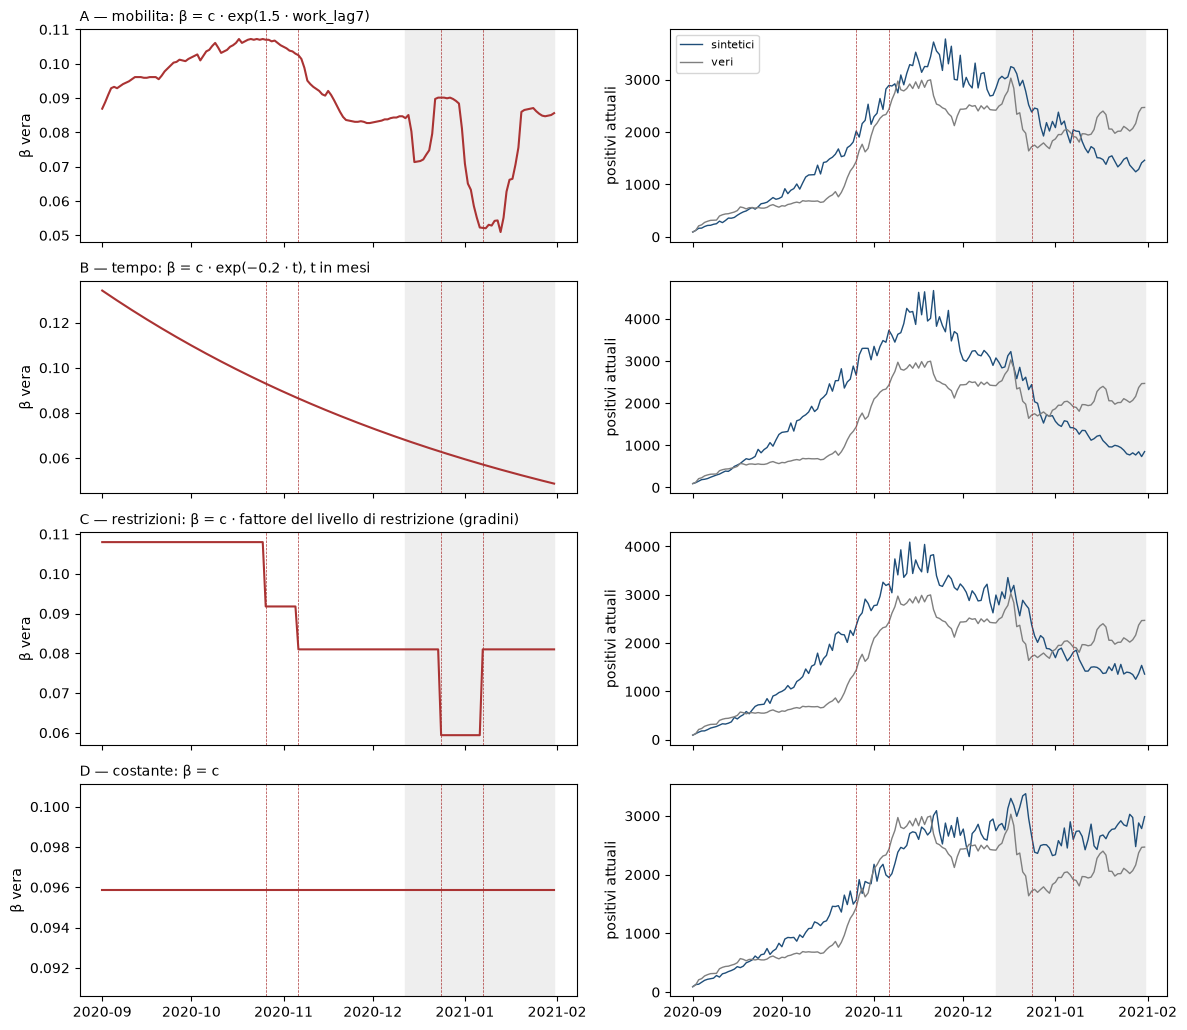

In [2]:
real = pd.read_csv(PROCESSED_DIR / "trento_clean.csv", index_col=0, parse_dates=True)
restr = load_restrictions()
fig, ax = plt.subplots(len(meta), 2, figsize=(12, 2.6 * len(meta)), sharex=True, squeeze=False)
for i, (k, d) in enumerate(data.items()):
    n_train = int(round(len(d) * 2 / 3))
    ax[i, 0].plot(d.index, d["beta vero"], color="#a33")
    ax[i, 0].set_ylabel("β vera")
    ax[i, 0].set_title(f"{k} — {meta[k]['nome']}: {meta[k]['formula vera']}", fontsize=10, loc="left")
    ax[i, 1].plot(d.index, d["totale_positivi"], color="#1f4e79", lw=1, label="sintetici")
    ax[i, 1].plot(d.index, real.loc[d.index, "totale_positivi"], color="#7f7f7f", lw=1, label="veri")
    ax[i, 1].set_ylabel("positivi attuali")
    for a in ax[i]:
        a.axvspan(d.index[n_train], d.index[-1], color="#eee")
        for s in restr.inizio[(restr.inizio > d.index[0]) & (restr.inizio <= d.index[-1])]:
            a.axvline(s, color="#a33", lw=0.5, ls="--")
ax[0, 1].legend(fontsize=8)
plt.tight_layout()

pd.DataFrame({k: {"β_cost": m["β_cost (baseline costante sui dati sintetici)"],
                  "livello vero": m["livello β (dati veri)"], "E0 vero": m["E0 vero"],
                  "E0 oracolo": m["oracolo E0"]} for k, m in meta.items()}).T.round(4)

## 2. Quanto errore resta anche con la β vera

L'**oracolo** è la formula vera valutata dentro la pipeline: è il meglio che il GP possa ottenere, e il termine di confronto per tutto il resto. Le altre colonne scompongono il suo errore:
- **solo rumore**: traiettoria vera senza rumore contro i dati rumorosi;
- **γ μ veri**: oracolo con i tassi usati per generare i dati, anche nel test;
- **γ μ veri congelati**: come sopra, ma con i tassi congelati nel test come nella pipeline. La differenza con la colonna precedente è l'effetto del **congelamento** nel test;
- **oracolo**: con γ e μ **stimati** dai dati (media mobile all'indietro di 7 giorni), come nella pipeline. La differenza con la colonna precedente è l'effetto della **stima** dei tassi, che è in ritardo rispetto a quelli veri.

Questa scomposizione vale anche per i dati veri: una parte dell'errore del notebook 06 non dipende da β, ma da come si stimano e si congelano γ e μ.

In [3]:
cols = ["solo rumore", "oracolo, γ μ veri", "oracolo, γ μ veri congelati", "oracolo"]
oracle_tab = pd.DataFrame({(k, p): {c: m[f"{c} {p}"] for c in cols}
                           for k, m in meta.items() for p in ("train", "test")}).T
oracle_tab.index.names = ["scenario", "periodo"]
oracle_tab.round(3)

solo rumore  oracolo, γ μ veri  oracolo, γ μ veri congelati  \
scenario periodo                                                                
A        train          0.105              0.097                        0.097   
         test           0.186              0.111                        0.598   
B        train          0.091              0.090                        0.090   
         test           0.136              0.116                        0.398   
C        train          0.075              0.073                        0.073   
         test           0.091              0.076                        0.508   
D        train          0.099              0.092                        0.092   
         test           0.170              0.167                        1.096   

                  oracolo  
scenario periodo           
A        train      0.121  
         test       0.579  
B        train      0.134  
         test       0.314  
C        train      0.136  
         test       0.457  
D        train      0.140  
         test       0.578

## 3. Errore del GP rispetto all'oracolo

Mediana e intervallo interquartile sui seed della formula scelta. `/ oracolo` = errore di test mediano diviso per l'errore di test dell'oracolo (1 = come la formula vera; < 1 è possibile per caso nel test, o perché una formula sbagliata compensa gli errori su γ e μ).

In [4]:
def iqr(x):
    q = x.quantile([.25, .75])
    return f"{q.iloc[0]:.2f}–{q.iloc[1]:.2f}"

summ = (chosen.groupby(["scenario", "config"])
        .agg(train=("train", "median"), test=("test", "median"), test_IQR=("test", iqr),
             nodi=("nodi", "median"), seed=("seed", "count"))
        .reindex(CONFIG_ORDER, level="config"))
summ["oracolo test"] = [meta[k]["oracolo test"] for k in summ.index.get_level_values("scenario")]
summ["/ oracolo"] = summ["test"] / summ["oracolo test"]
summ.to_csv(RESULTS_DIR / "05_sintetici_gp.csv")
display(summ.round(3))

ratio = (summ["test"].xs("mobilita", level="config") / summ["test"].xs("tempo", level="config")).rename("mobilità / tempo")
print(f"Rapporto fra gli errori di test mediani (sui dati veri: {REAL_RATIO})")
ratio.round(2)

train   test   test_IQR  nodi  seed  oracolo test  \
scenario config                                                              
A        tempo           0.106  0.595  0.59–0.59   5.0     5         0.579   
         mobilita        0.104  0.645  0.65–0.65   3.0     5         0.579   
         tempo+mobilita  0.104  0.645  0.65–0.65   3.0     5         0.579   
B        tempo           0.115  0.359  0.36–0.36   5.0     5         0.314   
         mobilita        0.118  0.415  0.41–0.41   3.0     5         0.314   
         tempo+mobilita  0.118  0.415  0.41–0.42   3.0     5         0.314   
C        tempo           0.131  0.597  0.60–0.60   5.0     5         0.457   
         mobilita        0.131  0.497  0.49–0.50   3.0     5         0.457   
         tempo+mobilita  0.131  0.497  0.49–0.50   3.0     5         0.457   
D        tempo           0.115  0.592  0.59–0.59   1.0     5         0.578   
         mobilita        0.115  0.592  0.59–0.59   1.0     5         0.578   
         tempo+mobilita  0.115  0.592  0.59–0.59   1.0     5         0.578   

                         / oracolo  
scenario config                     
A        tempo               1.027  
         mobilita            1.115  
         tempo+mobilita      1.115  
B        tempo               1.143  
         mobilita            1.322  
         tempo+mobilita      1.322  
C        tempo               1.305  
         mobilita            1.086  
         tempo+mobilita      1.086  
D        tempo               1.024  
         mobilita            1.025  
         tempo+mobilita      1.025

Rapporto fra gli errori di test mediani (sui dati veri: 0.48)


scenario
A    1.09
B    1.16
C    0.83
D    1.00
Name: mobilità / tempo, dtype: float64

## 4. Che cosa usano le formule scelte

Quota di formule (sui seed) che usano ciascun ingrediente, e ritardi di `work` usati. Nello scenario A la formula vera usa solo `work_lag7`; negli scenari B, C e D nessuna formula dovrebbe aver bisogno della mobilità.

In [5]:
use = (chosen.groupby(["scenario", "config"])[["usa mobilità", "usa work", "usa retail", "usa t", "quasi costante"]]
       .mean().reindex(CONFIG_ORDER, level="config"))
display(use.round(2))

mob = chosen[chosen["config"] != "tempo"]
lag_counts = (mob.explode("lag work").dropna(subset=["lag work"])
              .groupby(["scenario", "config", "lag work"]).size().unstack(fill_value=0))
print("Ritardi di work usati (numero di formule):")
lag_counts

usa mobilità  usa work  usa retail  usa t  \
scenario config                                                      
A        tempo                    0.0       0.0         0.0    1.0   
         mobilita                 1.0       0.6         0.4    0.0   
         tempo+mobilita           1.0       0.8         0.2    0.0   
B        tempo                    0.0       0.0         0.0    1.0   
         mobilita                 1.0       0.0         1.0    0.0   
         tempo+mobilita           1.0       0.2         1.0    0.0   
C        tempo                    0.0       0.0         0.0    1.0   
         mobilita                 1.0       0.2         1.0    0.0   
         tempo+mobilita           1.0       0.2         1.0    0.2   
D        tempo                    0.0       0.0         0.0    0.0   
         mobilita                 0.0       0.0         0.0    0.0   
         tempo+mobilita           0.0       0.0         0.0    0.0   

                         quasi costante  
scenario config                          
A        tempo                      0.0  
         mobilita                   0.0  
         tempo+mobilita             0.0  
B        tempo                      0.0  
         mobilita                   0.0  
         tempo+mobilita             0.0  
C        tempo                      0.0  
         mobilita                   0.0  
         tempo+mobilita             0.0  
D        tempo                      1.0  
         mobilita                   1.0  
         tempo+mobilita             1.0

Ritardi di work usati (numero di formule):


lag work                 0   3   14
scenario config                    
A        mobilita         2   1   0
         tempo+mobilita   3   1   0
B        tempo+mobilita   0   0   1
C        mobilita         1   0   1
         tempo+mobilita   1   0   1

## 5. Verifica dei criteri

In [6]:
def share(df, col):
    return df[col].mean() if len(df) else np.nan

checks = []
A = chosen[chosen["scenario"] == "A"]
if len(A):
    Am = A[A["config"] != "tempo"]
    w = Am[Am["usa work"]]
    lag7 = w["lag work"].apply(lambda l: 7 in l).mean() if len(w) else np.nan
    near = w["lag work"].apply(lambda l: len(l) > 0 and all(3 <= x <= 10 for x in l)).mean() if len(w) else np.nan
    checks += [
        ("A1", "formule con la mobilità che usano work", share(Am, "usa work"), f"≥ {CRIT['A1_work']}",
         share(Am, "usa work") >= CRIT["A1_work"]),
        ("A2", "di queste, con il ritardo 7", lag7, f"≥ {CRIT['A2_lag7']}", lag7 >= CRIT["A2_lag7"]),
        ("A2b", "di queste, solo ritardi fra 3 e 10", near, "(se A2 fallisce)", near >= CRIT["A2_lag7"]),
        ("A3", "tempo+mobilità: formule che usano t", share(A[A["config"] == "tempo+mobilita"], "usa t"),
         f"≤ {CRIT['A3_t_max']}", share(A[A["config"] == "tempo+mobilita"], "usa t") <= CRIT["A3_t_max"]),
    ]
for k in ["B", "C"]:
    if k in ratio.index:
        checks.append((k, "errore test mobilità / tempo (nessun effetto vero della mobilità)", ratio[k],
                       f"> {CRIT['BC_ratio']} (dati veri: {REAL_RATIO})", ratio[k] > CRIT["BC_ratio"]))
D = chosen[chosen["scenario"] == "D"]
if len(D):
    checks.append(("D1", "formule quasi costanti (β entro ±20%)", share(D, "quasi costante"),
                   f"≥ {CRIT['D1_flat']}", share(D, "quasi costante") >= CRIT["D1_flat"]))
for k, c in RIGHT_CONFIG.items():
    sel = summ.loc[k] if k in summ.index.get_level_values("scenario") else None
    if sel is None:
        continue
    x = sel.loc[c, "/ oracolo"] if c else sel["/ oracolo"].min()
    checks.append((f"{k}-oracolo", f"errore di test / oracolo ({c or 'migliore configurazione'})", x,
                   f"≤ {CRIT['oracle_x']}", x <= CRIT["oracle_x"]))
crit = pd.DataFrame(checks, columns=["criterio", "cosa", "valore", "soglia", "rispettato"]).set_index("criterio")
crit["valore"] = crit["valore"].astype(float).round(2)
crit

,cosa,valore,soglia,rispettato
criterio,,,,
A1,formule con la mobilità che usano work,0.70,≥ 0.6,True
A2,"di queste, con il ritardo 7",0.00,≥ 0.5,False
A2b,"di queste, solo ritardi fra 3 e 10",0.29,(se A2 fallisce),False
A3,tempo+mobilità: formule che usano t,0.00,≤ 0.3,True
B,errore test mobilità / tempo (nessun effetto v...,1.16,> 0.6 (dati veri: 0.48),True
C,errore test mobilità / tempo (nessun effetto v...,0.83,> 0.6 (dati veri: 0.48),True
D1,formule quasi costanti (β entro ±20%),1.00,≥ 0.6,True
A-oracolo,errore di test / oracolo (mobilita),1.12,≤ 1.5,True
B-oracolo,errore di test / oracolo (tempo),1.14,≤ 1.5,True


## 6. β(t) trovata contro β vera

Una curva per seed (blu), β vera in rosso. Il periodo di test è in grigio.

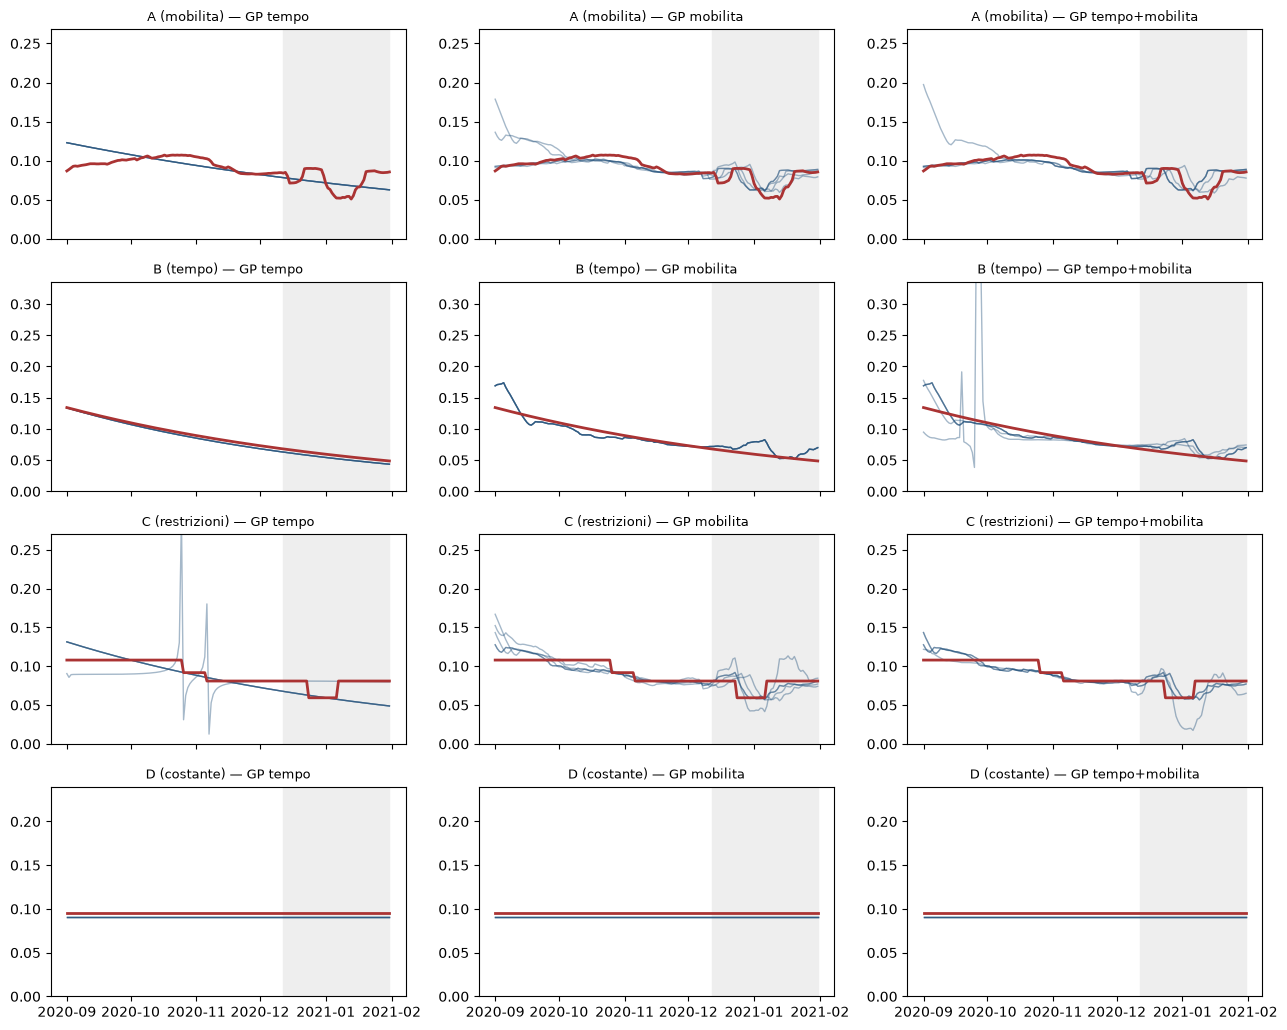

In [7]:
keys = [k for k in SCENARIOS if k in data]
fig, ax = plt.subplots(len(keys), len(CONFIG_ORDER), figsize=(13, 2.6 * len(keys)), sharex=True, squeeze=False)
for i, k in enumerate(keys):
    d = data[k]
    n_train = int(round(len(d) * 2 / 3))
    for j, c in enumerate(CONFIG_ORDER):
        a = ax[i, j]
        for _, r in chosen[(chosen["scenario"] == k) & (chosen["config"] == c)].iterrows():
            a.plot(d.index, r["beta"], color="#1f4e79", alpha=0.4, lw=1)
        a.plot(d.index, d["beta vero"], color="#a33", lw=2)
        a.axvspan(d.index[n_train], d.index[-1], color="#eee")
        a.set_title(f"{k} ({meta[k]['nome']}) — GP {c}", fontsize=9)
        a.set_ylim(0, 2.5 * d["beta vero"].max())
plt.tight_layout()

## 7. Lettura

Run con il vincolo $|g| \le 2$, $\sigma = 1/4$, 5 seed per scenario e configurazione (60 run). Le soglie sono quelle della tabella iniziale.

**Variabile sì, ritardo no (A1 ✓, A2 ✗).** Nello scenario A la β vera è $\beta(t) = \beta_{\text{cost}}\, e^{1.5\,\text{work}_{t-7}}$. Il 70% delle formule con la mobilità usa `work` (A1 rispettato) e nessuna usa `retail` dove c'è `work`; ma **nessuna** sceglie il ritardo 7: le formule scelte sono quasi tutte $g = \text{work}_{t-0} + c$ o $\text{work}_{t-3} + c$, con 3 nodi. Il coefficiente 1.5 sparisce (servirebbero 2 nodi in più, e la regola del 5% preferisce la formula corta) e il ritardo più corto compensa in parte l'ampiezza sbagliata. Questo è coerente con l'identificabilità: i dati vedono la combinazione $1/\sigma + \text{ritardo}$ e l'ampiezza dell'effetto, non i due separatamente, e i ritardi della mobilità sono fortemente correlati fra loro. **Conseguenza per il notebook 06:** il ritardo di 3 giorni trovato sui dati veri non va interpretato come un ritardo biologico o comportamentale; si può dire solo che la mobilità entra con un ritardo breve, nell'ordine di $0$–$7$ giorni.

**Falsi positivi: la mobilità fa da proxy, ma non abbastanza da spiegare i dati veri (B ✓, C ✓).** Senza effetto della mobilità, la configurazione "mobilità" la usa comunque sempre (soprattutto `retail`, che ha un andamento lento suo): in B `retail_lag14` imita il trend, in C `retail` segue gli scalini delle restrizioni e fa perfino meglio di "tempo" (rapporto 0.83). Il rapporto mobilità/tempo resta però fra 0.83 e 1.16, lontano dallo 0.48 dei dati veri. Quindi il vantaggio della mobilità nel notebook 06 è più grande di quello che un effetto proxy di questo tipo produce da solo; ma lo scenario C mostra che la mobilità può stare al posto delle restrizioni, per cui il confronto decisivo resta quello con la baseline a tratti (che sui dati veri la mobilità non batte).

**Nessuna struttura inventata (D1 ✓).** Con β costante tutte le formule scelte sono costanti (1 nodo), in tutte le configurazioni.

**Vicini all'oracolo, ma l'errore di test è dominato da γ e μ.** L'errore di test del GP è fra 1.02 e 1.14 volte quello della formula vera (soglia 1.5). Ma l'oracolo stesso passa da circa $0.1$ ($\gamma$, $\mu$ veri) a $0.4$–$1.1$ quando $\gamma$ e $\mu$ vengono congelati nel test: **la maggior parte dell'errore di test viene dal congelamento di γ e μ, non da β**. Per il notebook 06 questo significa che le differenze di errore di test fra configurazioni vanno lette come differenze relative, e che un errore di test assoluto alto non indica per forza una β sbagliata.

**In sintesi.** Il GP riconosce *se* conta la mobilità e quale variabile (A1, D1), non distingue in modo affidabile *quando* (A2), e può usare la mobilità come proxy di trend o restrizioni (B, C), anche se con un vantaggio molto minore di quello osservato sui dati veri.

**Limiti.** Una sola realizzazione del rumore per scenario; σ noto e uguale nel fit; stessa finestra; la β vera ha la stessa forma esponenziale usata dal GP nello scenario A (caso favorevole); i 5 seed cambiano solo il GP, non i dati, quindi la variabilità fra seed sottostima l'incertezza.
